In [1]:
#================================================================================================
# Cell 1

#=================================================================================================
# Install all required libraries for the entire project
! pip install plyfile open3d cloth-simulation-filter scipy matplotlib pandas scikit-learn tabulate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 MB 58.1 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 54.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 40.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 48.0 MB/s  0:00:00
  Created wheel for cloth-simulation-filter: filename=cloth_simulation_filter-1.1.7-cp313-cp313-linux_x86_64.whl size=1263221 sha256=199b7bb5f425758127e99fe16c0a3bb79d24e59a5ca692e604db15b65504f76e
  Stored in directory: /root/.cache/pip/wheels/54/e0/5a/93ee62e6f434662e2e00ad947094e8b03a9d72c5e0b1fe560a
Successfully built cloth-simulation-filter
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninstalled widgetsnbextension-3.6.10
  Attempting u

In [2]:
#====================================================
# Cell 2: Library Imports

#================================================
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import open3d as o3d
import CSF
from plyfile import PlyData, PlyElement
from scipy.spatial import cKDTree
from sklearn.metrics import confusion_matrix

In [3]:
# Mount Google Drive to access and save datasets/outputs
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
!pip -q install gdown
import gdown

gdown.download(
    "https://drive.google.com/uc?id=1kWci-4ggBouQB7FIH1jyKPbKVDwmYuxI",
    "/content/drive/MyDrive/Paris.ply",
    quiet=False
)

Downloading...
From (original): https://drive.google.com/uc?id=1kWci-4ggBouQB7FIH1jyKPbKVDwmYuxI
From (redirected): https://drive.google.com/uc?id=1kWci-4ggBouQB7FIH1jyKPbKVDwmYuxI&confirm=t&uuid=03415729-4621-45b4-a513-c18af148f9fb
To: /content/drive/MyDrive/Paris.ply
100%|██████████| 2.02G/2.02G [00:27<00:00, 72.7MB/s]


'/content/drive/MyDrive/Paris.ply'

Loading PLY file ... 
Total Count : 45,797,650 points
ply
format binary_little_endian 1.0
element vertex 45797650
property float x
property float y
property float z
property float x_origin
property float y_origin
property float z_origin
property double GPS_time
property float reflectance
property uint label
property uint class
end_header

Element Name: vertex
Total Count : 45,797,650 points
Properties :
  - x (f4)
  - y (f4)
  - z (f4)
  - x_origin (f4)
  - y_origin (f4)
  - z_origin (f4)
  - GPS_time (f8)
  - reflectance (f4)
  - label (u4)
  - class (u4)
Axis     Minimum     Maximum      Range
   X    9.483119   70.659859  61.176739
   Y -764.216553 -313.931732 450.284821
   Z   33.397121   65.293816  31.896694

Calculating median center and cropping...

Data extraction finished in 7.66 seconds.
Raw points extracted in 80x80m box: 10,567,437 points
Rendering full density plots...


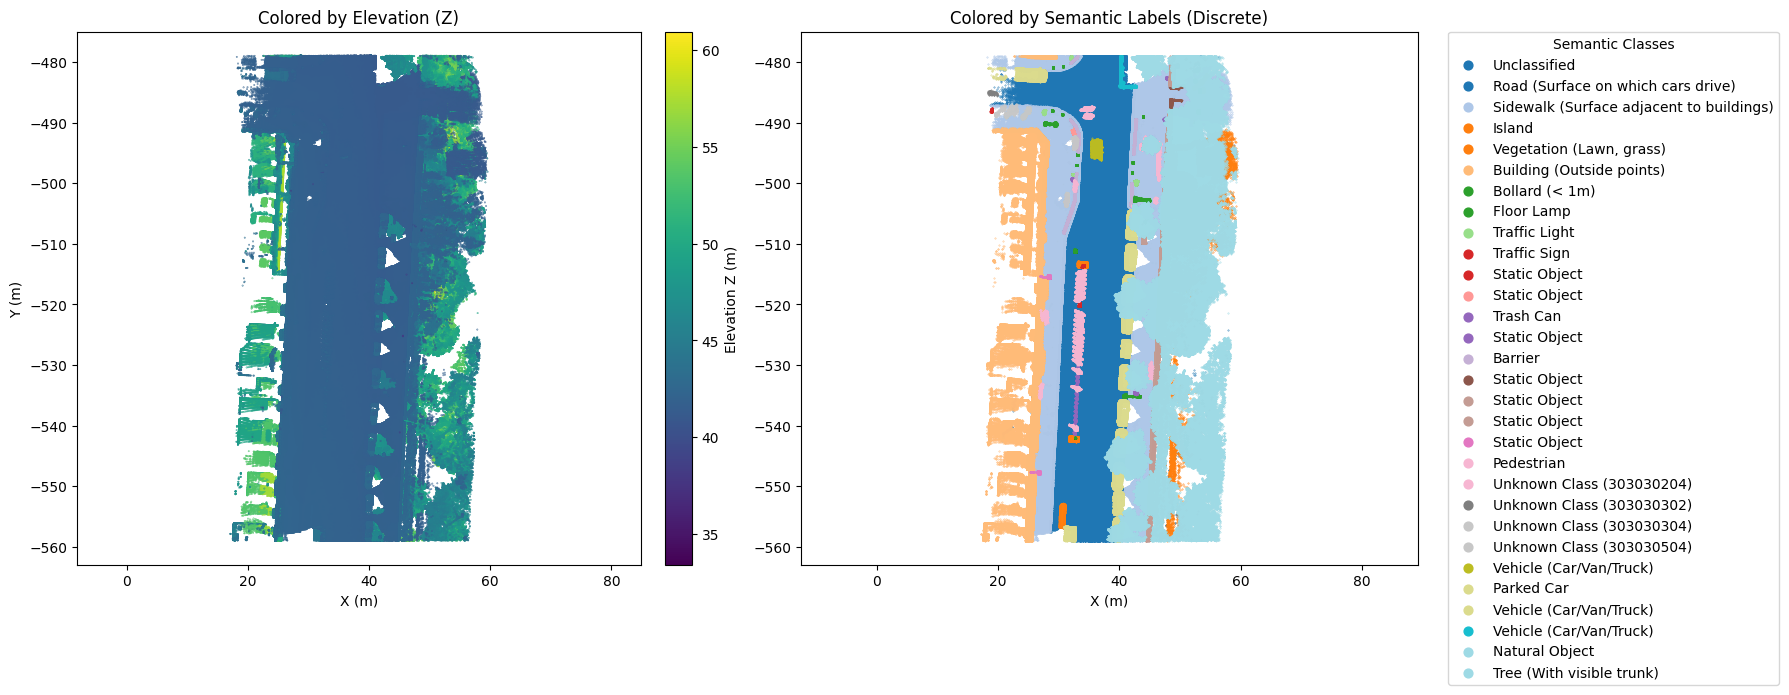

In [5]:
#================================================================================
# Cell 3: Header Inspection, Raw Point Cloud Ingestion & 80x80m Cropping
# Dictionary mapping based
NPM3D_CLASSES = {
    0: "Unclassified",
    100000000: "Other/Outliers",
    202010000: "Other Ground",
    202020000: "Road (Surface on which cars drive)",
    202030000: "Sidewalk (Surface adjacent to buildings)",
    202040000: "Curb (Vertical side of sidewalk)",
    202050000: "Island",
    202060000: "Vegetation (Lawn, grass)",
    203000000: "Building (Outside points)",
    302020200: "Post (> 1m)",
    302020300: "Bollard (< 1m)",
    302020400: "Floor Lamp",
    302020500: "Traffic Light",
    302020600: "Traffic Sign",
    302020900: "Trash Can",
    302030200: "Barrier",
    302040500: "Bench",
    303020300: "Walking Pedestrian",
    303040204: "Parked Car",
    304020000: "Tree (With visible trunk)",
    304030000: "Bush",
    304040000: "Potted Plant"

}

def get_class_name(class_id):
   """Fallback function to match sub-classes if exact ID is not in dict."""
   if class_id in NPM3D_CLASSES:
      return NPM3D_CLASSES[class_id]

   cid_str = str(class_id)
   if cid_str.startswith('30304'): return "Vehicle (Car/Van/Truck)"
   if cid_str.startswith('30302'): return "Pedestrian"
   if cid_str.startswith('304'): return "Natural Object"
   if cid_str.startswith('302'): return "Static Object"
   if cid_str.startswith('203'): return "Building"

   return f"Unknown Class ({class_id})"

# Define file path for the input PLY dataset
ply_path = '/content/drive/MyDrive/Paris.ply'

print("Loading PLY file ... ")
t_start = time. time()

# Read PLY data
with open(ply_path, 'rb') as f:
   plydata = PlyData.read(f)

vertex_el = plydata['vertex']
print(f"Total Count : {vertex_el.count:,} points")
print(plydata.header)

for element in plydata.elements:
    print(f"\nElement Name: {element.name}")
    print(f"Total Count : {element.count:,} points")
    print("Properties :")
    for prop in element.properties:
        print(f"  - {prop.name} ({prop.val_dtype})")

# Fast zero-copy memory access
vertex_data = vertex_el.data
all_x = vertex_data['x']
all_y = vertex_data['y']
all_z = vertex_data['z']
all_labels = vertex_data['class']

# Required report: full-file coordinate ranges (before cropping)
coordinate_table = pd.DataFrame({
    'Axis': ['X', 'Y', 'Z'],
    'Minimum': [np.min(all_x), np.min(all_y), np.min(all_z)],
    'Maximum': [np.max(all_x), np.max(all_y), np.max(all_z)],
    'Range': [np.ptp(all_x), np.ptp(all_y), np.ptp(all_z)]
})
print(coordinate_table.to_string(index=False))


print("\nCalculating median center and cropping...")
sample_stride = max(1, len(all_x) // 100000)
x_center = np.median(all_x[::sample_stride])
y_center = np.median(all_y[::sample_stride])
HALF_BOX = 40.0

# Sequential in-place masking for memory efficiency
roi_mask = (all_x >= x_center - HALF_BOX)
roi_mask &= (all_x <= x_center + HALF_BOX)
roi_mask &= (all_y >= y_center - HALF_BOX)
roi_mask &= (all_y <= y_center + HALF_BOX)

raw_pts = np.column_stack((all_x[roi_mask], all_y[roi_mask], all_z[roi_mask]))
raw_labels = all_labels[roi_mask]

t_end = time.time()
print(f"\nData extraction finished in {t_end - t_start:.2f} seconds.")
print(f"Raw points extracted in 80x80m box: {len(raw_pts):,} points")


# ==========================================
# Plotting
# ==========================================
print("Rendering full density plots...")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Continuous Elevation map (Z)
sc1 = axes[0].scatter(raw_pts[:, 0], raw_pts[:, 1], c=raw_pts[:, 2], cmap='viridis', s=0.1)
plt.colorbar(sc1, ax=axes[0], label='Elevation Z (m)', fraction=0.046, pad=0.04)
axes[0].set_title('Colored by Elevation (Z)')
axes[0].set_xlabel('X (m)')
axes[0].set_ylabel('Y (m)')
axes[0].axis('equal')

# Plot 2: Discrete Semantic map with explicit Legend
unique_labels = np.unique(raw_labels)
color_palette = plt.get_cmap('tab20', len(unique_labels))(np.linspace(0, 1, len(unique_labels)))

for i, lbl in enumerate(unique_labels):
    mask = (raw_labels == lbl)
    class_name = get_class_name(lbl)
    axes[1].scatter(raw_pts[mask, 0], raw_pts[mask, 1],
                    color=color_palette[i], s=0.1, label=class_name)

axes[1].set_title('Colored by Semantic Labels (Discrete)')
axes[1].set_xlabel('X (m)')
axes[1].axis('equal')

# Create a legend and place it outside the plot area
leg = axes[1].legend(title="Semantic Classes", bbox_to_anchor=(1.05, 1),
                     loc='upper left', borderaxespad=0.)
for handle in leg.legend_handles:
    handle._sizes = [40]

plt.tight_layout()
plt.show()

Points entering SOR: 2,394,901


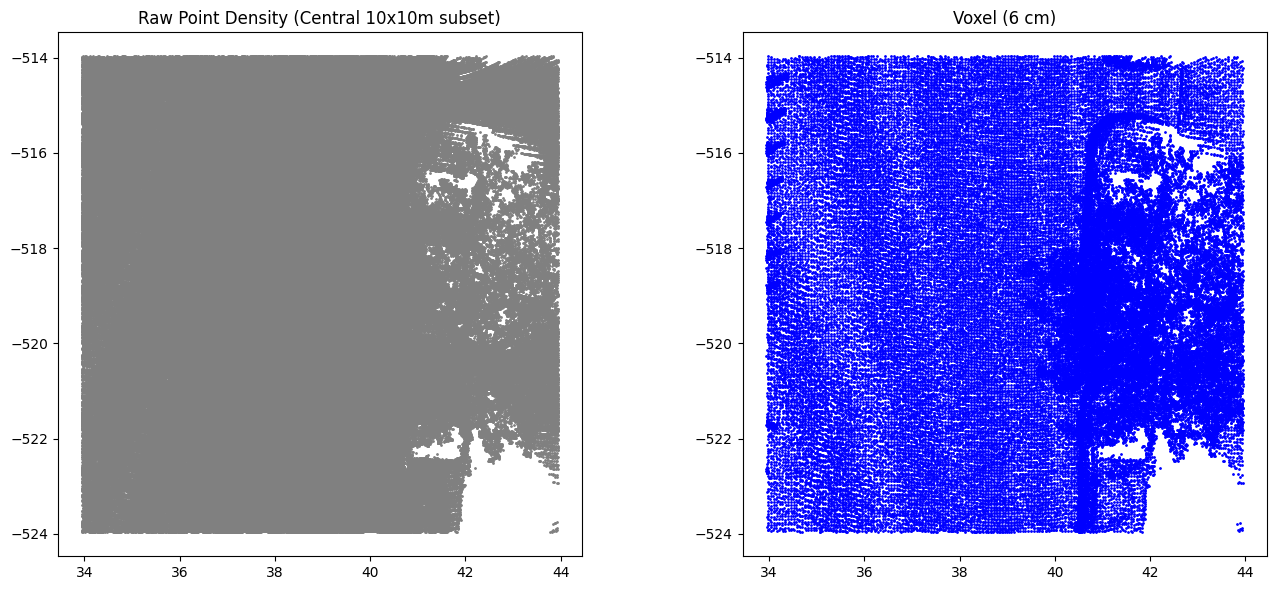

In [8]:
# ==============================================================================
# Cell 4: Density Equalization - 3D Voxel Grid Subsampling
# ==============================================================================
# Keep the teacher's voxel method available.
# False: main exercise uses raw extracted points for SOR.
# True: repeat the teacher's 6 cm voxel preprocessing; state this in the report.
USE_VOXEL = True

# Initialize Open3D point cloud object with raw points
if USE_VOXEL:
    pcd_raw = o3d.geometry.PointCloud()
    pcd_raw.points = o3d.utility.Vector3dVector(raw_pts)

    # Apply Voxel grid subsampling (Voxel size = 6 cm)
    voxel_size = 0.06
    pcd_down = pcd_raw.voxel_down_sample(voxel_size=voxel_size)

    # Find nearest original points to the new voxel centroids to inherit Ground Truth labels
    tree = cKDTree(raw_pts)
    _, voxel_indices = tree.query(np.asarray(pcd_down.points))

    voxel_pts = raw_pts[voxel_indices]
    voxel_labels = raw_labels[voxel_indices]
else:
    # Names kept unchanged so the following teacher cells still work.
    voxel_pts = raw_pts
    voxel_labels = raw_labels

# Print the reduction statistics
print(f"Points entering SOR: {len(voxel_pts):,}")

# Plot: Compare Raw vs Voxel Subsampled density using a central 10x10m spatial subset
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

subset_mask_raw = (np.abs(raw_pts[:, 0] - x_center) < 5) & (np.abs(raw_pts[:, 1] - y_center) < 5)
subset_mask_vox = (np.abs(voxel_pts[:, 0] - x_center) < 5) & (np.abs(voxel_pts[:, 1] - y_center) < 5)

axes[0].scatter(raw_pts[subset_mask_raw, 0], raw_pts[subset_mask_raw, 1], c='gray', s=1)
axes[0].set_title('Raw Point Density (Central 10x10m subset)')
axes[0].set_aspect('equal')

axes[1].scatter(voxel_pts[subset_mask_vox, 0], voxel_pts[subset_mask_vox, 1], c='blue', s=1)
axes[1].set_title('Voxel (6 cm)' if USE_VOXEL else 'Raw points (voxel disabled)')
axes[1].set_aspect('equal')

plt.tight_layout()
plt.show()

SOR (k=16, std_ratio=2) | Time: 11.017s
Points after SOR filtering: 2,306,080 (Removed 88,821 outliers)
Inliers %: 96.29% | Outliers %: 3.71%


/tmp/ipykernel_803/794955295.py:52: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


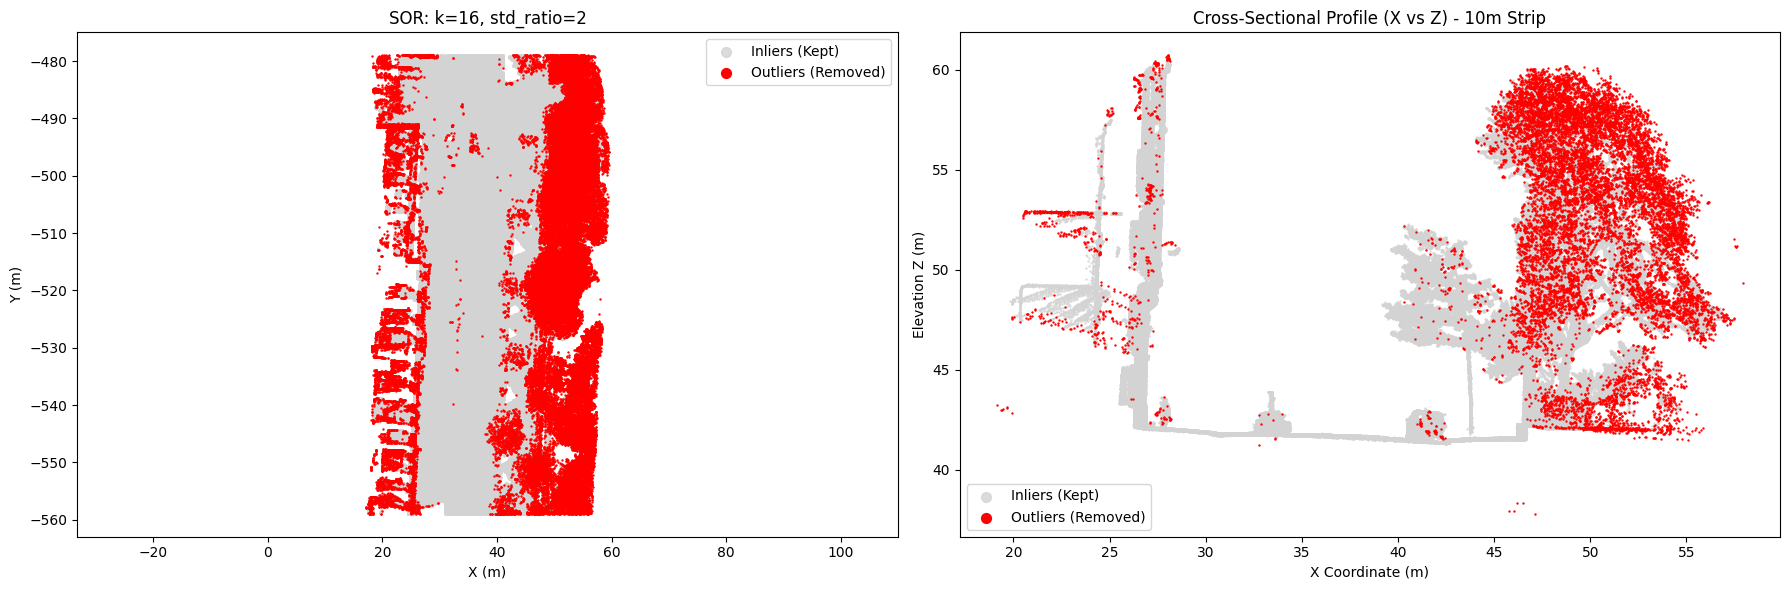


SOR (k=16, std_ratio=3) | Time: 12.522s
Points after SOR filtering: 2,354,353 (Removed 40,548 outliers)
Inliers %: 98.31% | Outliers %: 1.69%


/tmp/ipykernel_803/794955295.py:98: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


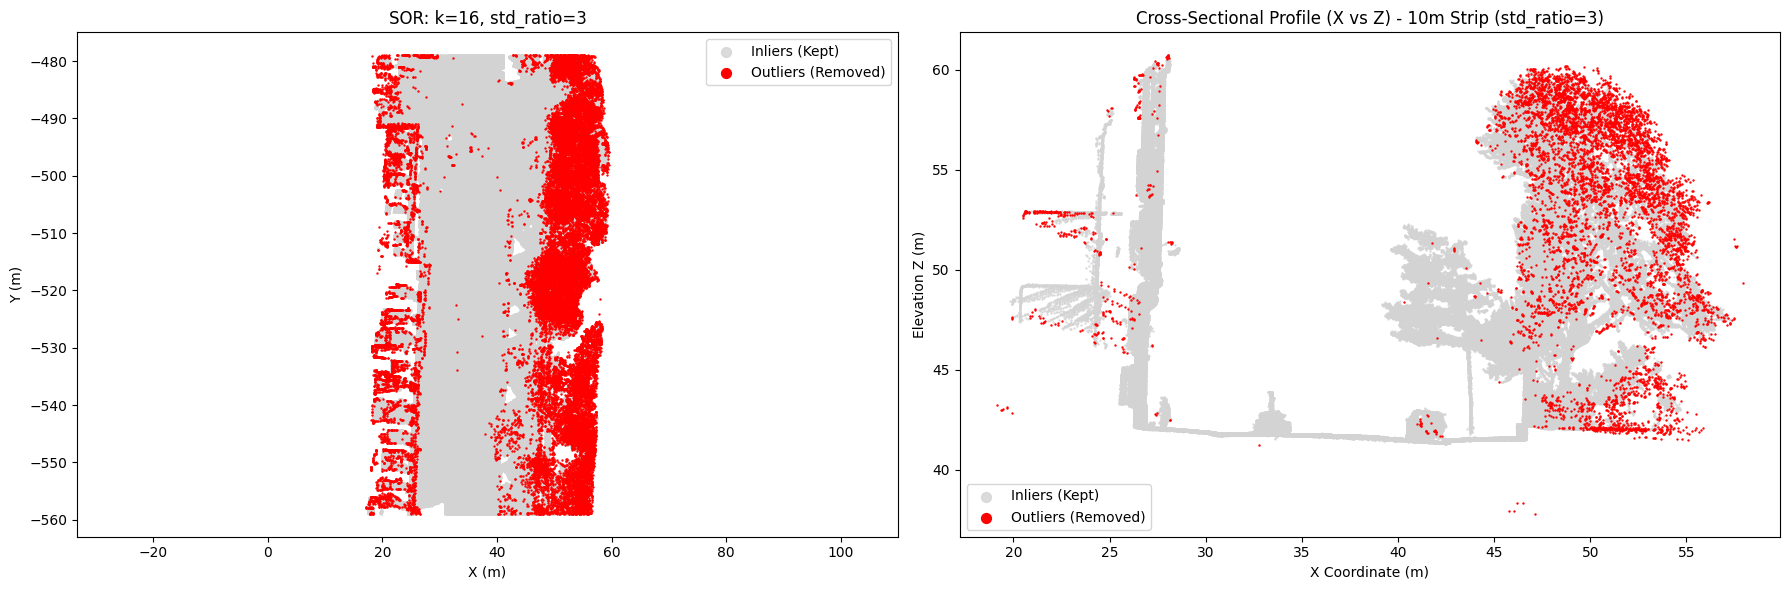

In [10]:
# ==============================================================================
# Cell 5: Statistical Outlier Removal (SOR)
# ==============================================================================
# Initialize Open3D PointCloud object
pcd_voxel = o3d.geometry.PointCloud()
pcd_voxel.points = o3d.utility.Vector3dVector(voxel_pts)

# PARAMETERS: nb_neighbors=16, std_ratio=2.0  (changed from 50 / 5.0)
t_sor1 = time.perf_counter()
cl, sor_indices = pcd_voxel.remove_statistical_outlier(nb_neighbors=16, std_ratio=2.0)
t_sor1 = time.perf_counter() - t_sor1

# Extract Inliers and Outliers
filtered_pts = voxel_pts[sor_indices]
filtered_labels = voxel_labels[sor_indices]

outlier_mask = np.ones(len(voxel_pts), dtype=bool)
outlier_mask[sor_indices] = False
outlier_pts = voxel_pts[outlier_mask]

print(f"SOR (k=16, std_ratio=2) | Time: {t_sor1:.3f}s")
print(f"Points after SOR filtering: {len(filtered_pts):,} (Removed {len(outlier_pts):,} outliers)")
print(f"Inliers %: {len(filtered_pts)/len(voxel_pts)*100:.2f}% | Outliers %: {len(outlier_pts)/len(voxel_pts)*100:.2f}%")

# Plotting: Fixed Marker Sizes for True Representation
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel 1: Top-Down View
axes[0].scatter(filtered_pts[:, 0], filtered_pts[:, 1], c='lightgrey', s=0.5, alpha=0.8, label='Inliers (Kept)')
axes[0].scatter(outlier_pts[:, 0], outlier_pts[:, 1], c='red', s=0.5, marker='o', alpha=1.0, label='Outliers (Removed)')
axes[0].set_title('SOR: k=16, std_ratio=2')
axes[0].set_xlabel('X (m)')
axes[0].set_ylabel('Y (m)')
axes[0].legend(markerscale=10)
axes[0].axis('equal')

# Panel 2: Cross-Sectional Profile (10m Strip)
slice_width = 10.0
slice_mask_inliers = np.abs(filtered_pts[:, 1] - y_center) < (slice_width / 2.0)
slice_mask_outliers = np.abs(outlier_pts[:, 1] - y_center) < (slice_width / 2.0)

inliers_slice = filtered_pts[slice_mask_inliers]
outliers_slice = outlier_pts[slice_mask_outliers]

axes[1].scatter(inliers_slice[:, 0], inliers_slice[:, 2], c='lightgrey', s=0.5, alpha=0.8, label='Inliers (Kept)')
axes[1].scatter(outliers_slice[:, 0], outliers_slice[:, 2], c='red', s=0.5, marker='o', alpha=1.0, label='Outliers (Removed)')
axes[1].set_title('Cross-Sectional Profile (X vs Z) - 10m Strip')
axes[1].set_xlabel('X Coordinate (m)')
axes[1].set_ylabel('Elevation Z (m)')
axes[1].legend(markerscale=10)

plt.tight_layout()
plt.show()

# ==============================================================================
# Run 2: std_ratio = 3.0
# ==============================================================================
t_sor2 = time.perf_counter()
cl_2, sor_indices_2 = pcd_voxel.remove_statistical_outlier(nb_neighbors=16, std_ratio=3.0)
t_sor2 = time.perf_counter() - t_sor2

filtered_pts_2 = voxel_pts[sor_indices_2]
filtered_labels_2 = voxel_labels[sor_indices_2]

outlier_mask_2 = np.ones(len(voxel_pts), dtype=bool)
outlier_mask_2[sor_indices_2] = False
outlier_pts_2 = voxel_pts[outlier_mask_2]

print(f"\nSOR (k=16, std_ratio=3) | Time: {t_sor2:.3f}s")
print(f"Points after SOR filtering: {len(filtered_pts_2):,} (Removed {len(outlier_pts_2):,} outliers)")
print(f"Inliers %: {len(filtered_pts_2)/len(voxel_pts)*100:.2f}% | Outliers %: {len(outlier_pts_2)/len(voxel_pts)*100:.2f}%")

# ---- Select std_ratio=3 as the optimal case for the next stage ----
filtered_pts = filtered_pts_2
filtered_labels = filtered_labels_2

# Plot: Run 2
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].scatter(filtered_pts_2[:, 0], filtered_pts_2[:, 1], c='lightgrey', s=0.5, alpha=0.8, label='Inliers (Kept)')
axes[0].scatter(outlier_pts_2[:, 0], outlier_pts_2[:, 1], c='red', s=0.5, marker='o', alpha=1.0, label='Outliers (Removed)')
axes[0].set_title('SOR: k=16, std_ratio=3')
axes[0].set_xlabel('X (m)')
axes[0].set_ylabel('Y (m)')
axes[0].legend(markerscale=10)
axes[0].axis('equal')

slice_mask_inliers_2 = np.abs(filtered_pts_2[:, 1] - y_center) < (slice_width / 2.0)
slice_mask_outliers_2 = np.abs(outlier_pts_2[:, 1] - y_center) < (slice_width / 2.0)

axes[1].scatter(filtered_pts_2[slice_mask_inliers_2, 0], filtered_pts_2[slice_mask_inliers_2, 2], c='lightgrey', s=0.5, alpha=0.8, label='Inliers (Kept)')
axes[1].scatter(outlier_pts_2[slice_mask_outliers_2, 0], outlier_pts_2[slice_mask_outliers_2, 2], c='red', s=0.5, marker='o', alpha=1.0, label='Outliers (Removed)')
axes[1].set_title('Cross-Sectional Profile (X vs Z) - 10m Strip (std_ratio=3)')
axes[1].set_xlabel('X Coordinate (m)')
axes[1].set_ylabel('Elevation Z (m)')
axes[1].legend(markerscale=10)

plt.tight_layout()
plt.show()

--- CSF rigidness = 1 ---
Execution finished in    : 1.885 seconds
Classified as Ground     : 667,567 points (28.35%)
Classified as Non-Ground : 1,686,786 points (71.65%)

--- CSF rigidness = 2 ---
Execution finished in    : 1.859 seconds
Classified as Ground     : 661,399 points (28.09%)
Classified as Non-Ground : 1,692,954 points (71.91%)


/tmp/ipykernel_803/1683936311.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


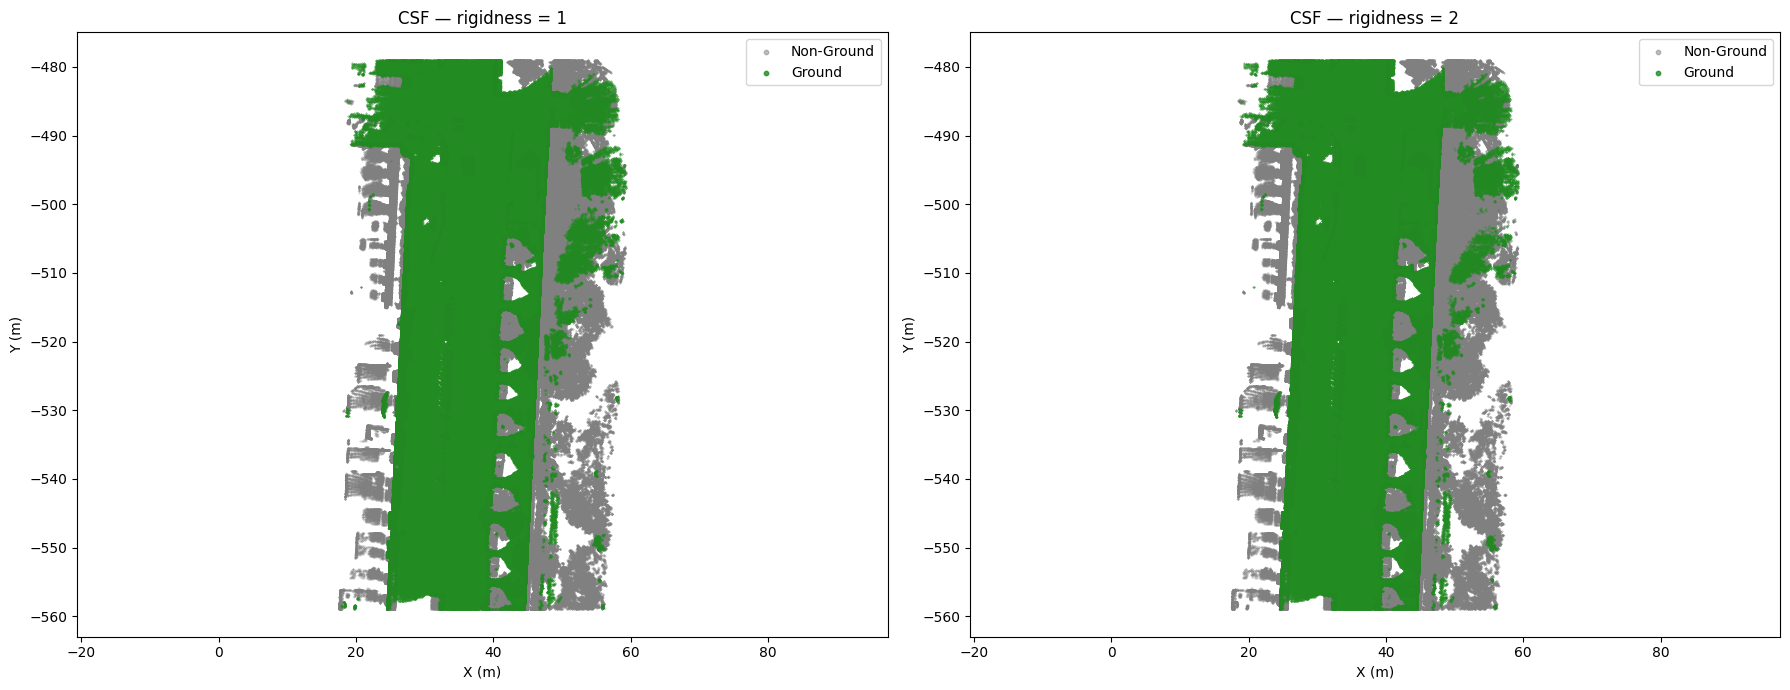

In [14]:
# ==============================================================================
# Cell 6: Ground Filtering - Cloth Simulation Filtering (CSF)
# ==============================================================================

# ---- Run 1: rigidness = 1 ----
t_start = time.perf_counter()

csf_solver = CSF.CSF()

csf_solver.params.bSloopSmooth    = True
csf_solver.params.cloth_resolution = 0.8
csf_solver.params.class_threshold  = 0.30
csf_solver.params.rigidness        = 1
csf_solver.params.time_step        = 0.65

csf_solver.setPointCloud(filtered_pts.tolist())

ground_indices_1     = CSF.VecInt()
non_ground_indices_1 = CSF.VecInt()
csf_solver.do_filtering(ground_indices_1, non_ground_indices_1, False)

t_csf_1 = time.perf_counter() - t_start

csf_ground_mask_1 = np.zeros(len(filtered_pts), dtype=bool)
csf_ground_mask_1[np.array(ground_indices_1)] = True

print(f"--- CSF rigidness = 1 ---")
print(f"Execution finished in    : {t_csf_1:.3f} seconds")
print(f"Classified as Ground     : {csf_ground_mask_1.sum():,} points "
      f"({csf_ground_mask_1.sum()/len(filtered_pts)*100:.2f}%)")
print(f"Classified as Non-Ground : {(~csf_ground_mask_1).sum():,} points "
      f"({(~csf_ground_mask_1).sum()/len(filtered_pts)*100:.2f}%)")


# ---- Run 2: rigidness = 2 ----
t_start = time.perf_counter()

csf_solver = CSF.CSF()

csf_solver.params.bSloopSmooth    = True
csf_solver.params.cloth_resolution = 0.8
csf_solver.params.class_threshold  = 0.30
csf_solver.params.rigidness        = 2
csf_solver.params.time_step        = 0.65

csf_solver.setPointCloud(filtered_pts.tolist())

ground_indices_2     = CSF.VecInt()
non_ground_indices_2 = CSF.VecInt()
csf_solver.do_filtering(ground_indices_2, non_ground_indices_2, False)

t_csf_2 = time.perf_counter() - t_start

csf_ground_mask_2 = np.zeros(len(filtered_pts), dtype=bool)
csf_ground_mask_2[np.array(ground_indices_2)] = True

print(f"\n--- CSF rigidness = 2 ---")
print(f"Execution finished in    : {t_csf_2:.3f} seconds")
print(f"Classified as Ground     : {csf_ground_mask_2.sum():,} points "
      f"({csf_ground_mask_2.sum()/len(filtered_pts)*100:.2f}%)")
print(f"Classified as Non-Ground : {(~csf_ground_mask_2).sum():,} points "
      f"({(~csf_ground_mask_2).sum()/len(filtered_pts)*100:.2f}%)")


# ---- Select rigidness = 2 as optimal for the next stage ----
csf_ground_mask = csf_ground_mask_2
t_csf = t_csf_2


# ---- Plot: visual comparison ----
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].scatter(filtered_pts[~csf_ground_mask_1, 0], filtered_pts[~csf_ground_mask_1, 1],
                c='gray', s=0.1, alpha=0.5, label='Non-Ground')
axes[0].scatter(filtered_pts[csf_ground_mask_1, 0], filtered_pts[csf_ground_mask_1, 1],
                c='forestgreen', s=0.1, alpha=0.8, label='Ground')
axes[0].set_title('CSF — rigidness = 1')
axes[0].set_xlabel('X (m)'); axes[0].set_ylabel('Y (m)')
axes[0].legend(markerscale=10); axes[0].axis('equal')

axes[1].scatter(filtered_pts[~csf_ground_mask_2, 0], filtered_pts[~csf_ground_mask_2, 1],
                c='gray', s=0.1, alpha=0.5, label='Non-Ground')
axes[1].scatter(filtered_pts[csf_ground_mask_2, 0], filtered_pts[csf_ground_mask_2, 1],
                c='forestgreen', s=0.1, alpha=0.8, label='Ground')
axes[1].set_title('CSF — rigidness = 2')
axes[1].set_xlabel('X (m)'); axes[1].set_ylabel('Y (m)')
axes[1].legend(markerscale=10); axes[1].axis('equal')

plt.tight_layout()
plt.show()

| Total Evaluated Points   | True Positive (TP)   | True Negative (TN)   | False Positive (FP - Type II)   | False Negative (FN - Type I)   | Type I Error (%)   | Type II Error (%)   | Total Accuracy (%)   |
|:-------------------------|:---------------------|:---------------------|:--------------------------------|:-------------------------------|:-------------------|:--------------------|:---------------------|
| 2,354,353                | 616,660              | 1,675,580            | 44,739                          | 17,374                         | 2.74%              | 2.60%               | 97.36%               |


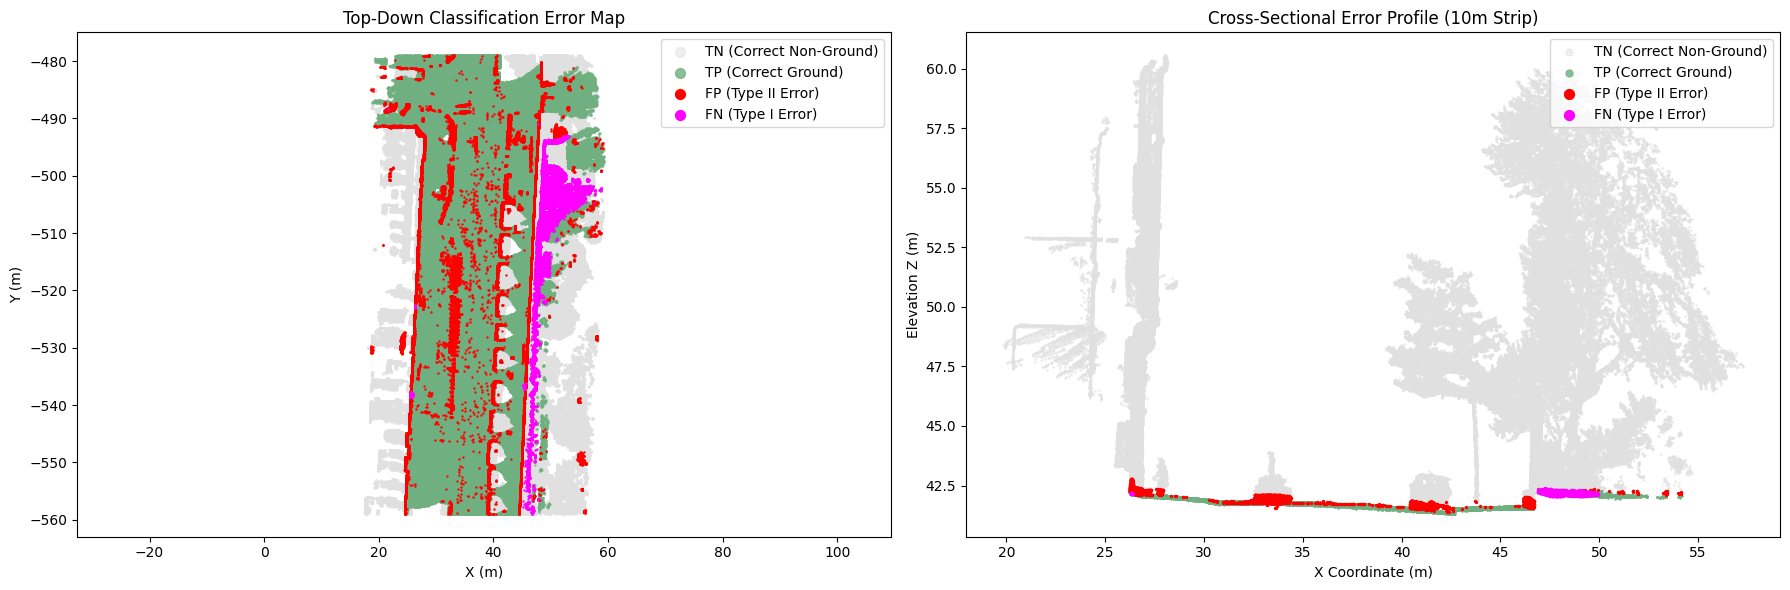

In [15]:
# ==============================================================================
# Cell 7: Quantitative Evaluation (Confusion Matrix & Spatial Error Map)
# ==============================================================================

# Standard NPM3D Ground Class IDs
TRUE_GROUND_CLASSES = [202020000, 202030000, 202050000, 202060000]
actual_ground_mask = np.isin(filtered_labels, TRUE_GROUND_CLASSES)

# Compute binary Confusion Matrix variables
tn, fp, fn, tp = confusion_matrix(actual_ground_mask, csf_ground_mask).ravel()

# Calculate performance metrics
type_i_error = (fn / (tp + fn)) * 100.0  # Omission Error
type_ii_error = (fp / (tn + fp)) * 100.0 # Commission Error
overall_accuracy = ((tp + tn) / (tp + tn + fp + fn)) * 100.0

summary_table = [
    {"Total Evaluated Points": f"{len(filtered_pts):,}",
     "True Positive (TP)": f"{tp:,}",
     "True Negative (TN)": f"{tn:,}",
     "False Positive (FP - Type II)": f"{fp:,}",
     "False Negative (FN - Type I)": f"{fn:,}",
     "Type I Error (%)": f"{type_i_error:.2f}%",
     "Type II Error (%)": f"{type_ii_error:.2f}%",
     "Total Accuracy (%)": f"{overall_accuracy:.2f}%"}
]
print(pd.DataFrame(summary_table).to_markdown(index=False))

# Plotting: Top-Down Error Map and Cross-Sectional Profile
tp_mask = actual_ground_mask & csf_ground_mask
tn_mask = (~actual_ground_mask) & (~csf_ground_mask)
fp_mask = (~actual_ground_mask) & csf_ground_mask
fn_mask = actual_ground_mask & (~csf_ground_mask)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Panel 1: Top-Down Spatial Error Map
axes[0].scatter(filtered_pts[tn_mask, 0], filtered_pts[tn_mask, 1], c='#e0e0e0', s=0.5, alpha=0.5, label='TN (Correct Non-Ground)')
axes[0].scatter(filtered_pts[tp_mask, 0], filtered_pts[tp_mask, 1], c='#70b080', s=0.5, alpha=0.8, label='TP (Correct Ground)')
axes[0].scatter(filtered_pts[fp_mask, 0], filtered_pts[fp_mask, 1], c='red', s=0.5, alpha=1.0, label='FP (Type II Error)')
axes[0].scatter(filtered_pts[fn_mask, 0], filtered_pts[fn_mask, 1], c='magenta', s=0.5, alpha=1.0, label='FN (Type I Error)')
axes[0].set_title('Top-Down Classification Error Map')
axes[0].set_xlabel('X (m)')
axes[0].set_ylabel('Y (m)')
axes[0].legend(markerscale=10, loc='upper right')
axes[0].axis('equal')

# Panel 2: Cross-Sectional Profile
slice_width = 10.0
slice_mask = np.abs(filtered_pts[:, 1] - y_center) < (slice_width / 2.0)

tn_slice = tn_mask & slice_mask
tp_slice = tp_mask & slice_mask
fp_slice = fp_mask & slice_mask
fn_slice = fn_mask & slice_mask

axes[1].scatter(filtered_pts[tn_slice, 0], filtered_pts[tn_slice, 2], c='#e0e0e0', s=1.0, alpha=0.5, label='TN (Correct Non-Ground)')
axes[1].scatter(filtered_pts[tp_slice, 0], filtered_pts[tp_slice, 2], c='#70b080', s=1.0, alpha=0.8, label='TP (Correct Ground)')
axes[1].scatter(filtered_pts[fp_slice, 0], filtered_pts[fp_slice, 2], c='red', s=2.0, alpha=1.0, label='FP (Type II Error)')
axes[1].scatter(filtered_pts[fn_slice, 0], filtered_pts[fn_slice, 2], c='magenta', s=2.0, alpha=1.0, label='FN (Type I Error)')
axes[1].set_title('Cross-Sectional Error Profile (10m Strip)')
axes[1].set_xlabel('X Coordinate (m)')
axes[1].set_ylabel('Elevation Z (m)')
axes[1].legend(markerscale=5, loc='upper right')

plt.tight_layout()
plt.show()

In [18]:
# ==============================================================================
# Cell 8: Exporting All Models to Google Drive as PLY format
# ==============================================================================
# 1. Define the output directory path in Google Drive
output_dir = '/content/LIDAR_OUT'
os.makedirs(output_dir, exist_ok=True)

print(f"Output directory ready: {output_dir}\n")

# ==============================================================================
# Helper Function to Save Points to PLY
# ==============================================================================
def save_ply(points, filename):
    """
    Saves an N x 3 numpy array as a PLY point cloud using Open3D.
    """
    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points)
    o3d.io.write_point_cloud(os.path.join(output_dir, filename), pcd)

# ==============================================================================
# Exporting Point Clouds (Ground and Non-Ground)
# ==============================================================================
# Split the original points based on the CSF ground mask (created in Cell 5)
ground_pts = filtered_pts[csf_ground_mask]
non_ground_pts = filtered_pts[~csf_ground_mask]

print("1/2: Exporting Point Clouds (.ply)...")
save_ply(ground_pts, "../../Desktop/project1-kianaAbbasabadi/Ground_Points.ply")
save_ply(non_ground_pts, "../../Desktop/project1-kianaAbbasabadi/Non_Ground_Points.ply")
print("  -> Ground and Non-Ground PLY files saved successfully.")

# ==============================================================================
# Exporting Raster Models as PLY Point Clouds
# ==============================================================================
def raster_to_ply(array, filename, x_start, y_start, res):
    """
    Converts a 2D raster array back to 3D X, Y, Z points and saves as PLY.
    Empty cells (NaN or Inf) are automatically filtered out.
    """
    rows, cols = array.shape

    # Create coordinate grids based on origin and resolution
    x_coords = x_start + np.arange(cols) * res
    y_coords = y_start + np.arange(rows) * res
    X, Y = np.meshgrid(x_coords, y_coords)

    # Filter out NoData (NaN or Inf) values
    valid_mask = ~np.isnan(array) & ~np.isinf(array)

    # Stack into N x 3 valid points
    pts = np.column_stack((X[valid_mask], Y[valid_mask], array[valid_mask]))

    # Save using the helper function
    save_ply(pts, filename)

Output directory ready: /content/LIDAR_OUT

1/2: Exporting Point Clouds (.ply)...
  -> Ground and Non-Ground PLY files saved successfully.


In [19]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/LIDAR_Results",
    "zip",
    "/content/LIDAR_OUT"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

for n, a in zip('XYZ', [all_x, all_y, all_z]):
    print(f"{n}: min={a.min():.2f}  max={a.max():.2f}  range={a.max()-a.min():.2f}")


print(f"قبل از SOR : {voxel_pts[:,2].min():.2f}  تا  {voxel_pts[:,2].max():.2f}  (دامنه {np.ptp(voxel_pts[:,2]):.2f})")
print(f"بعد از SOR : {filtered_pts[:,2].min():.2f}  تا  {filtered_pts[:,2].max():.2f}  (دامنه {np.ptp(filtered_pts[:,2]):.2f})")


rows = []
for c in np.unique(filtered_labels[~actual_ground_mask]):
    m = (filtered_labels == c)
    correct = (~csf_ground_mask[m]).sum()   # درست: غیرزمین تشخیص داده شده
    wrong   = csf_ground_mask[m].sum()      # اشتباه: زمین تشخیص داده شده
    rows.append((c, get_class_name(c), m.sum(), correct, wrong, correct/m.sum()*100))
print(pd.DataFrame(rows, columns=['code','class','total','correct','wrong','correct_%']).to_string(index=False))

X: min=9.48  max=70.66  range=61.18
Y: min=-764.22  max=-313.93  range=450.28
Z: min=33.40  max=65.29  range=31.90
قبل از SOR : 33.40  تا  60.96  (دامنه 27.57)
بعد از SOR : 40.36  تا  60.71  (دامنه 20.35)
     code                     class  total  correct  wrong  correct_%
        0              Unclassified   6134      955   5179  15.568960
203000000 Building (Outside points) 630795   620798   9997  98.415175
302020300            Bollard (< 1m)   1528     1082    446  70.811518
302020400                Floor Lamp   5971     5838    133  97.772567
302020500             Traffic Light   3218     3064    154  95.214419
302020600              Traffic Sign    897      858     39  95.652174
302020700             Static Object    805      686    119  85.217391
302020800             Static Object   1069      930    139  86.997194
302020900                 Trash Can   1636     1183    453  72.310513
302021100             Static Object   1247      822    425  65.918204
302030200                